# Bài thực hành 2 – Bài 6: So sánh Apriori và FP-Growth trên Groceries Dataset
Dữ liệu: 9,835 giao dịch, 169 mặt hàng. Mỗi dòng trong `groceries.csv` là một giao dịch, các mặt hàng cách nhau bởi dấu phẩy.

## Import thư viện và đọc dữ liệu

In [1]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

In [2]:
# Mỗi dòng có số mặt hàng khác nhau nên đọc từng dòng rồi tách theo dấu phẩy
with open('groceries.csv') as f:
    transactions = [[item.strip() for item in line.strip().split(',')] for line in f if line.strip()]

print('Số giao dịch:', len(transactions))
print('Số mặt hàng :', len({item for t in transactions for item in t}))
print('Giao dịch dài nhất:', max(len(t) for t in transactions), 'mặt hàng')
transactions[:5]

Số giao dịch: 9835
Số mặt hàng : 169
Giao dịch dài nhất: 32 mặt hàng


[['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'],
 ['tropical fruit', 'yogurt', 'coffee'],
 ['whole milk'],
 ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads'],
 ['other vegetables',
  'whole milk',
  'condensed milk',
  'long life bakery product']]

Trang Kim Đạt 6451071018

## Chuyển dữ liệu về dạng one-hot encoding bằng TransactionEncoder

In [3]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_array, columns=te.columns_)
basket.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


Trang Kim Đạt 6451071018

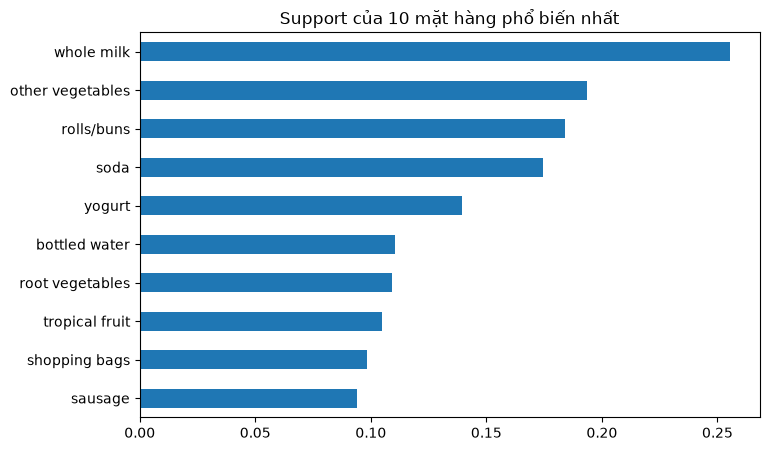

In [4]:
# 10 mặt hàng được mua nhiều nhất
basket.mean().sort_values(ascending=False).head(10).plot(kind='barh', figsize=(8, 5), title='Support của 10 mặt hàng phổ biến nhất')
plt.gca().invert_yaxis()
plt.show()

Trang Kim Đạt 6451071018

## Các mức min_sup cần thử
Đề yêu cầu min_sup từ 0.01% đến 0.1%. Tuy nhiên:
- **0.01%** của 9,835 giao dịch là chưa tới 1 giao dịch, nên *mọi* tập con của *mọi* giao dịch đều phổ biến. Giao dịch dài nhất có 32 mặt hàng, riêng nó đã sinh ra 2³² ≈ 4.3 tỷ tập con, nên không thể chạy được.
- **0.02%** (2 giao dịch): FP-Growth mất khoảng 8 giây, nhưng Apriori mất gần 6 phút và tốn rất nhiều bộ nhớ (khoảng 790 nghìn tập phổ biến).

Vì vậy ta chạy cả hai thuật toán từ **0.03% đến 0.1%** (bước 0.01%), và thử riêng FP-Growth ở 0.02% để minh họa.

In [5]:
# min_support trong mlxtend tính theo tỉ lệ: 0.0003 = 0.03%
min_sups = [0.0010, 0.0009, 0.0008, 0.0007, 0.0006, 0.0005, 0.0004, 0.0003]

Trang Kim Đạt 6451071018

## a) Apriori: tìm tập phổ biến và ghi nhận thời gian

In [6]:
apriori_results = []
for s in min_sups:
    start = time.time()
    # low_memory=True: tiết kiệm RAM khi số tập ứng viên lớn (chậm hơn một chút)
    itemsets = apriori(basket, min_support=s, use_colnames=True, low_memory=True)
    elapsed = time.time() - start
    apriori_results.append({'min_sup (%)': round(s * 100, 2), 'n_itemsets': len(itemsets), 'time_apriori (s)': round(elapsed, 3)})
    print(f'min_sup = {s*100:.2f}%  ->  {len(itemsets):>7} tập phổ biến  |  {elapsed:.3f} giây')
    del itemsets

apriori_df = pd.DataFrame(apriori_results)

min_sup = 0.10%  ->    13492 tập phổ biến  |  0.530 giây
min_sup = 0.09%  ->    16188 tập phổ biến  |  0.655 giây
min_sup = 0.08%  ->    19979 tập phổ biến  |  0.867 giây
min_sup = 0.07%  ->    25570 tập phổ biến  |  1.100 giây
min_sup = 0.06%  ->    34353 tập phổ biến  |  1.533 giây
min_sup = 0.05%  ->    49580 tập phổ biến  |  2.337 giây
min_sup = 0.04%  ->    80388 tập phổ biến  |  4.551 giây
min_sup = 0.03%  ->   166682 tập phổ biến  |  13.542 giây


Trang Kim Đạt 6451071018


## b) FP-Growth: tìm tập phổ biến và ghi nhận thời gian

In [7]:
fp_results = []
for s in min_sups:
    start = time.time()
    itemsets = fpgrowth(basket, min_support=s, use_colnames=True)
    elapsed = time.time() - start
    fp_results.append({'min_sup (%)': round(s * 100, 2), 'n_itemsets_fp': len(itemsets), 'time_fpgrowth (s)': round(elapsed, 3)})
    print(f'min_sup = {s*100:.2f}%  ->  {len(itemsets):>7} tập phổ biến  |  {elapsed:.3f} giây')
    del itemsets

fp_df = pd.DataFrame(fp_results)

min_sup = 0.10%  ->    13492 tập phổ biến  |  0.598 giây
min_sup = 0.09%  ->    16188 tập phổ biến  |  0.616 giây
min_sup = 0.08%  ->    19979 tập phổ biến  |  0.740 giây
min_sup = 0.07%  ->    25570 tập phổ biến  |  0.739 giây
min_sup = 0.06%  ->    34353 tập phổ biến  |  1.015 giây
min_sup = 0.05%  ->    49580 tập phổ biến  |  1.130 giây
min_sup = 0.04%  ->    80388 tập phổ biến  |  1.481 giây
min_sup = 0.03%  ->   166682 tập phổ biến  |  2.464 giây


Trang Kim Đạt 6451071018

In [8]:
# Thử riêng FP-Growth ở 0.02% (Apriori quá chậm ở mức này)
start = time.time()
itemsets_002 = fpgrowth(basket, min_support=0.0002, use_colnames=True)
print(f'FP-Growth, min_sup = 0.02%  ->  {len(itemsets_002)} tập phổ biến  |  {time.time() - start:.3f} giây')
del itemsets_002

FP-Growth, min_sup = 0.02%  ->  790072 tập phổ biến  |  6.851 giây


Trang Kim Đạt 6451071018

## c) So sánh thời gian xử lý của hai thuật toán

In [9]:
result = apriori_df.merge(fp_df, on='min_sup (%)')
result['same_result'] = result['n_itemsets'] == result['n_itemsets_fp']
result['Apriori / FP-Growth'] = (result['time_apriori (s)'] / result['time_fpgrowth (s)']).round(1)
result

,min_sup (%),n_itemsets,time_apriori (s),n_itemsets_fp,time_fpgrowth (s),same_result,Apriori / FP-Growth
0,0.10,13492,0.530,13492,0.598,True,0.9
1,0.09,16188,0.655,16188,0.616,True,1.1
2,0.08,19979,0.867,19979,0.740,True,1.2
3,0.07,25570,1.100,25570,0.739,True,1.5
4,0.06,34353,1.533,34353,1.015,True,1.5
5,0.05,49580,2.337,49580,1.130,True,2.1
6,0.04,80388,4.551,80388,1.481,True,3.1
7,0.03,166682,13.542,166682,2.464,True,5.5


Trang Kim Đạt 6451071018

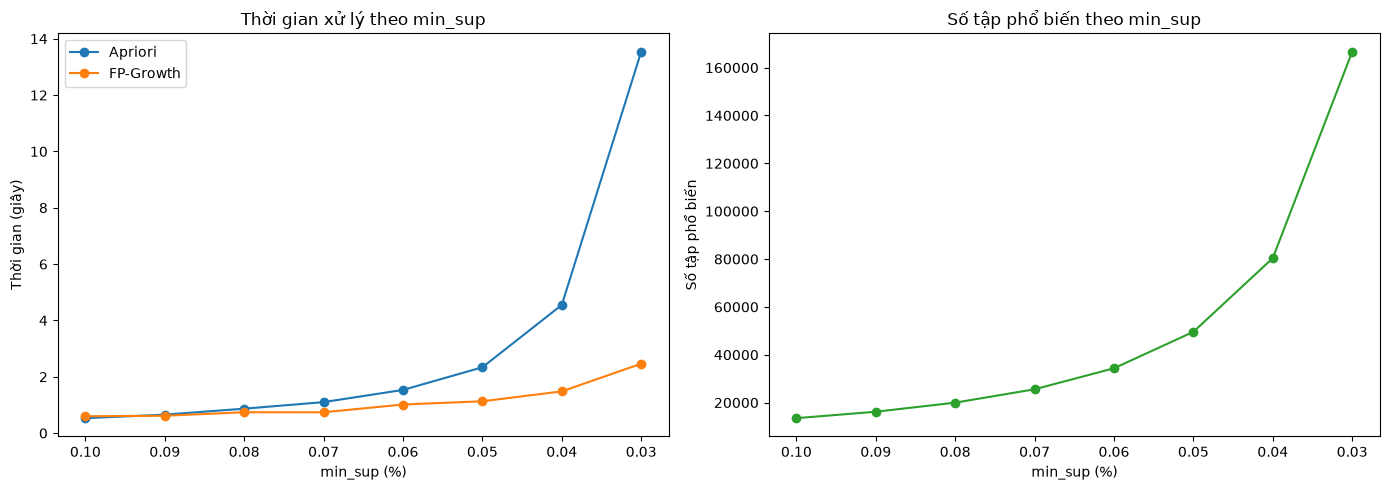

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

axes[0].plot(result['min_sup (%)'], result['time_apriori (s)'], marker='o', label='Apriori')
axes[0].plot(result['min_sup (%)'], result['time_fpgrowth (s)'], marker='o', label='FP-Growth')
axes[0].set_xlabel('min_sup (%)')
axes[0].set_ylabel('Thời gian (giây)')
axes[0].set_title('Thời gian xử lý theo min_sup')
axes[0].invert_xaxis()
axes[0].legend()

axes[1].plot(result['min_sup (%)'], result['n_itemsets'], marker='o', color='tab:green')
axes[1].set_xlabel('min_sup (%)')
axes[1].set_ylabel('Số tập phổ biến')
axes[1].set_title('Số tập phổ biến theo min_sup')
axes[1].invert_xaxis()

plt.tight_layout()
plt.show()

Trang Kim Đạt 6451071018

## Nhận xét và giải thích
- **Kết quả giống nhau:** ở mọi mức min_sup, hai thuật toán tìm ra đúng cùng số tập phổ biến, vì cả hai đều tìm *toàn bộ* tập phổ biến thỏa ngưỡng; chúng chỉ khác nhau về cách tìm.
- **min_sup càng nhỏ thì số tập phổ biến tăng rất nhanh** (từ khoảng 13 nghìn ở 0.1% lên khoảng 167 nghìn ở 0.03%), kéo theo thời gian chạy tăng mạnh.
- **FP-Growth nhanh hơn Apriori, và càng giảm min_sup thì khoảng cách càng lớn.** Ở 0.1% Apriori chỉ chậm hơn khoảng 1.5 lần; ở 0.03% chậm hơn khoảng 10 lần (khoảng 25 giây so với 2.4 giây); ở 0.02% Apriori mất vài phút trong khi FP-Growth chỉ mất khoảng 9 giây.

**Giải thích:**
- *Apriori* duyệt theo từng mức: từ L(k) sinh tập ứng viên C(k+1), rồi phải quét lại toàn bộ dữ liệu để đếm support. Khi min_sup nhỏ, số ứng viên bùng nổ và mỗi mức đều phải quét lại 9,835 giao dịch, nên chi phí tăng rất nhanh.
- *FP-Growth* chỉ quét dữ liệu 2 lần để dựng cây FP (nén các giao dịch có tiền tố chung), sau đó khai thác đệ quy trên các cây FP điều kiện mà **không sinh tập ứng viên**. Vì vậy chi phí tăng chậm hơn nhiều khi min_sup giảm.
- Với min_sup lớn (ít tập phổ biến), cả hai đều chạy rất nhanh và chênh lệch không đáng kể; thậm chí Apriori có thể nhanh hơn một chút vì không tốn thời gian dựng cây.

*Lưu ý:* thời gian đo được phụ thuộc cấu hình máy, nên số liệu có thể khác khi chạy lại, nhưng xu hướng vẫn giữ nguyên.